# 10 Compare Cosines With the Original Processing

Do the new processing steps give cue-cue cosines that are close to the original (2019) ones?

- **New:** features from `processed/09_cue_feature_counts.csv`; the cosine is computed on `prop_final` (the share of a cue's people who listed the word).
  - **16% only** (what was asked for): keep features listed by 16% or more of a cue's people.
  - **16% or top five** (the 2019 rule), shown beside it so the difference is visible.
- **Original:** the root-word cosines in Word-Norms-2 (`4 analysis/datasets/all root values.txt`), Buchanan cue pairs only. Only pairs with a non-zero cosine are in that file, so a missing pair is a cosine of 0. The 2019 script (`dotcosine.pl`) only wrote a cosine when two cues shared **more than one** feature, so the same rule is applied to the new cosines.

Output: `processed/10_cosine_comparison.csv` (every pair, 16% only), `processed/10_cosine_summary.csv` and `processed/10_cosine_comparison.png`.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import sparse
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt

ORIGINAL = Path("/Users/erinbuchanan/GitHub/Research/3_published/46 Word-Norms-2/4 analysis/datasets/all root values.txt")
CUTOFF = 0.16

## Original cosines

In [2]:
orig = pd.read_csv(ORIGINAL, sep=r"\s+", header=None, names=["a", "b", "cosine_original"],
                   dtype={"a": str, "b": str}, keep_default_na=False, engine="python")
orig = orig[(orig["a"].str[0] == "b") & (orig["b"].str[0] == "b")]       # Buchanan cues only
orig["cue1"], orig["cue2"] = orig["a"].str[1:], orig["b"].str[1:]
orig = orig[orig["cue1"] != orig["cue2"]]
swap = orig["cue1"] > orig["cue2"]
orig.loc[swap, ["cue1", "cue2"]] = orig.loc[swap, ["cue2", "cue1"]].values
orig = orig[["cue1", "cue2", "cosine_original"]].drop_duplicates(["cue1", "cue2"])
print(f"{len(orig):,} cue pairs with a cosine above 0")

40,138 cue pairs with a cosine above 0


## New cosines

In [3]:
counts = pd.read_csv("processed/09_cue_feature_counts.csv", keep_default_na=False)
cues = sorted(counts["cue"].unique())
cue_index = {c: i for i, c in enumerate(cues)}

def new_cosines(kept):
    """Cue-cue cosines from the kept features; a pair needs 2 or more shared features."""
    features = sorted(kept["word"].unique())
    feature_index = {f: i for i, f in enumerate(features)}
    matrix = sparse.csr_matrix(
        (kept["prop_final"].values, (kept["cue"].map(cue_index).values, kept["word"].map(feature_index).values)),
        shape=(len(cues), len(features)),
    )
    norms = np.sqrt(matrix.multiply(matrix).sum(axis=1)).A1
    norms[norms == 0] = 1
    cosine = (matrix @ matrix.T).toarray() / np.outer(norms, norms)
    np.fill_diagonal(cosine, 0)
    present = (matrix > 0).astype(np.int32)
    cosine[(present @ present.T).toarray() < 2] = 0
    rows, cols = np.triu_indices(len(cues), k=1)
    mask = cosine[rows, cols] > 0
    return pd.DataFrame({"cue1": np.array(cues)[rows[mask]], "cue2": np.array(cues)[cols[mask]],
                         "cosine_new": cosine[rows, cols][mask]})

only16 = counts[counts["prop_final"] >= CUTOFF]
top5 = counts.sort_values(["cue", "count", "word"], ascending=[True, False, True]).groupby("cue").head(5)
rule_2019 = pd.concat([only16, top5]).drop_duplicates(["cue", "word"])
print(f"16% only: {len(only16):,} cue-word pairs ({only16['cue'].nunique():,} cues)")
print(f"16% or top five: {len(rule_2019):,} cue-word pairs")

16% only: 18,412 cue-word pairs (3,698 cues)
16% or top five: 22,020 cue-word pairs


## Compare

In [4]:
def compare(new, label):
    pairs = new.merge(orig, on=["cue1", "cue2"], how="outer")
    pairs[["cosine_new", "cosine_original"]] = pairs[["cosine_new", "cosine_original"]].fillna(0)
    pairs = pairs[pairs["cue1"].isin(cue_index) & pairs["cue2"].isin(cue_index)].sort_values(["cue1", "cue2"])
    both = pairs[(pairs["cosine_new"] > 0) & (pairs["cosine_original"] > 0)]

    def top_neighbours(col, k=10):
        d = pd.concat([pairs[["cue1", "cue2", col]].rename(columns={"cue1": "cue", "cue2": "other"}),
                       pairs[["cue2", "cue1", col]].rename(columns={"cue2": "cue", "cue1": "other"})])
        d = d[d[col] > 0].sort_values(["cue", col], ascending=[True, False])
        return d.groupby("cue").head(k).groupby("cue")["other"].apply(set)
    t_orig, t_new = top_neighbours("cosine_original"), top_neighbours("cosine_new")
    enough = [c for c in t_orig.index.intersection(t_new.index) if len(t_orig[c]) >= 10]
    overlap = pd.Series({c: len(t_orig[c] & t_new[c]) / 10 for c in enough})

    summary = {
        "pairs with a cosine > 0 in the original": int((pairs["cosine_original"] > 0).sum()),
        "pairs with a cosine > 0 in the new": int((pairs["cosine_new"] > 0).sum()),
        "pairs in both": len(both),
        "pairs only in the original": int(((pairs["cosine_original"] > 0) & (pairs["cosine_new"] == 0)).sum()),
        "pairs only in the new": int(((pairs["cosine_original"] == 0) & (pairs["cosine_new"] > 0)).sum()),
        "mean cosine, original (pairs in both)": round(both["cosine_original"].mean(), 3),
        "mean cosine, new (pairs in both)": round(both["cosine_new"].mean(), 3),
        "Pearson r, pairs in both": round(pearsonr(both.cosine_original, both.cosine_new)[0], 3),
        "Spearman rho, pairs in both": round(spearmanr(both.cosine_original, both.cosine_new)[0], 3),
        "mean absolute difference, pairs in both": round((both.cosine_original - both.cosine_new).abs().mean(), 3),
        "Pearson r, all pairs (missing = 0)": round(pearsonr(pairs.cosine_original, pairs.cosine_new)[0], 3),
        "mean share of the original top-10 neighbours also in the new top 10": round(overlap.mean(), 3),
        "cues in that comparison": len(enough),
    }
    return pairs, both, overlap, pd.Series(summary, name=label)

pairs16, both16, overlap16, s16 = compare(new_cosines(only16), "16% only")
pairs19, both19, overlap19, s19 = compare(new_cosines(rule_2019), "16% or top five (2019 rule)")
summary = pd.concat([s16, s19], axis=1)
summary.to_csv("processed/10_cosine_summary.csv")
pairs16.to_csv("processed/10_cosine_comparison.csv", index=False)
summary

,16% only,16% or top five (2019 rule)
pairs with a cosine > 0 in the original,40107.000,40107.000
pairs with a cosine > 0 in the new,17326.000,22411.000
pairs in both,14161.000,17210.000
pairs only in the original,25946.000,22897.000
pairs only in the new,3165.000,5201.000
"mean cosine, original (pairs in both)",0.362,0.360
"mean cosine, new (pairs in both)",0.361,0.353
"Pearson r, pairs in both",0.908,0.901
"Spearman rho, pairs in both",0.910,0.901
"mean absolute difference, pairs in both",0.052,0.052


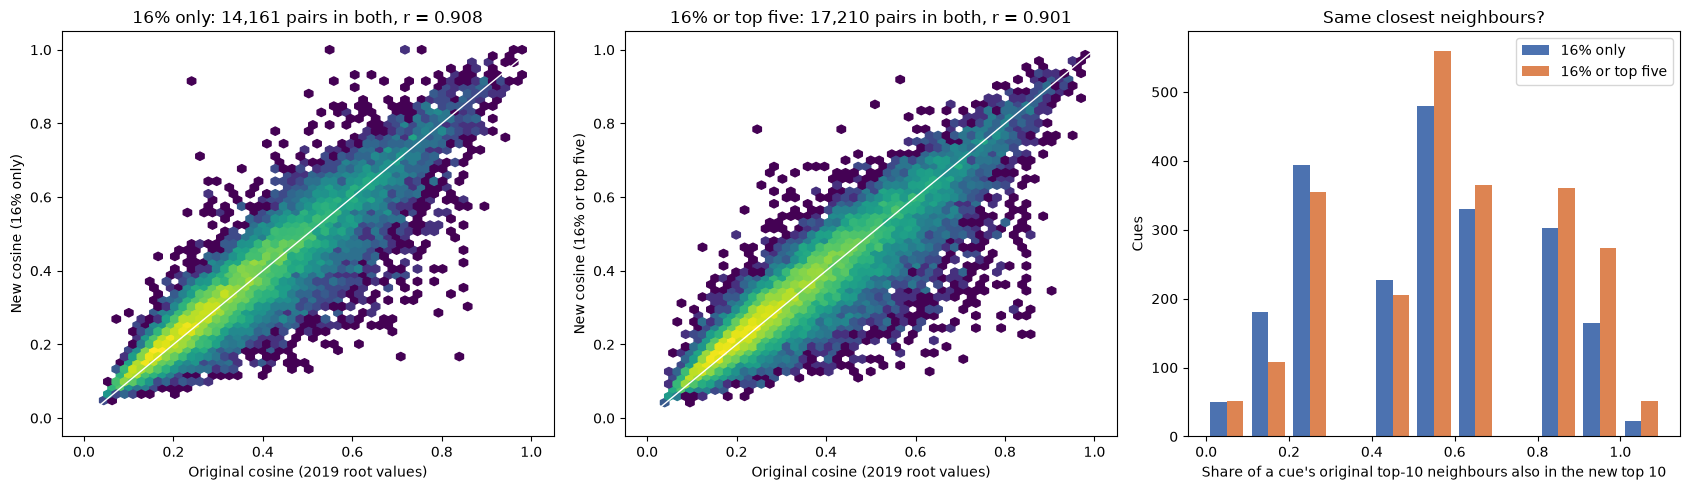

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, both, label, s in [(axes[0], both16, "16% only", s16), (axes[1], both19, "16% or top five", s19)]:
    ax.hexbin(both["cosine_original"], both["cosine_new"], gridsize=50, bins="log", cmap="viridis", mincnt=1)
    ax.plot([0, 1], [0, 1], color="white", linewidth=1)
    ax.set_xlabel("Original cosine (2019 root values)")
    ax.set_ylabel(f"New cosine ({label})")
    ax.set_title(f"{label}: {len(both):,} pairs in both, r = {s['Pearson r, pairs in both']}")
axes[2].hist([overlap16, overlap19], bins=11, range=(0, 1.1), label=["16% only", "16% or top five"], color=["#4c72b0", "#dd8452"])
axes[2].set_xlabel("Share of a cue's original top-10 neighbours also in the new top 10")
axes[2].set_ylabel("Cues")
axes[2].legend()
axes[2].set_title("Same closest neighbours?")
plt.tight_layout()
plt.savefig("processed/10_cosine_comparison.png", dpi=150)
plt.show()